# 11 · End to end: retrieval at pilot scale, the secondary benchmark, latency

Three records:

* `retrieval-pilot.json`: 500-candidate pools per labelled JD, Recall@k of final-set fits,
  and retrieve-then-rank. The 490 distractors are unjudged, so recall is an upper bound.
* `a1-metrics.json`: the text rungs on A1, the secondary benchmark. **A1's labels do not
  reproduce (A13)**, so these measure agreement with A1's labelling, not quality.
* `latency.json`: system time per 500-candidate role, on the machine named in the record.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from candidate_screener import reporting
from candidate_screener.config import OUTPUT

reporting.style(plt)
pilot = json.loads((OUTPUT / "matching" / "retrieval-pilot.json").read_text(encoding="utf-8"))
a1 = json.loads((OUTPUT / "matching" / "a1-metrics.json").read_text(encoding="utf-8"))
latency = json.loads((OUTPUT / "matching" / "latency.json").read_text(encoding="utf-8"))
print(pilot["note"])

Relevant = final-set Fit among the JD's 10 labelled candidates; the 490 distractors are unjudged and assumed not fits (upper-bound recall).


## Retrieval: do the fits survive into a 50-candidate shortlist?

Provisional S2 bar: Recall@50 ≥ 0.80 (classical) / ≥ 0.90 (advanced).

In [2]:
rows = []
for name, figs in pilot["retrievers"].items():
    f = {(x["metric"], x["scope"]): x for x in figs}
    rows.append({"retriever": name, **{m: round(f[(m, "total")]["value"], 3)
                                       for m in ("recall@10", "recall@50", "recall@100")},
                 "recall@50 CI": f"[{f[('recall@50', 'total')]['ci_low']:.2f}, {f[('recall@50', 'total')]['ci_high']:.2f}]"})
pd.DataFrame(rows).sort_values("recall@50", ascending=False)

,retriever,recall@10,recall@50,recall@100,recall@50 CI
8,metadata + SBERT (weak fine-tuned),0.432,0.936,0.987,"[0.90, 0.97]"
6,metadata + TF-IDF,0.477,0.929,0.986,"[0.88, 0.97]"
1,metadata rules,0.426,0.924,0.963,"[0.88, 0.96]"
7,metadata + SBERT (zero-shot),0.461,0.924,0.987,"[0.87, 0.96]"
2,TF-IDF,0.265,0.658,0.786,"[0.59, 0.73]"
5,SBERT (weak fine-tuned),0.212,0.616,0.809,"[0.54, 0.69]"
4,SBERT (zero-shot),0.173,0.449,0.639,"[0.38, 0.52]"
3,BM25,0.151,0.340,0.461,"[0.29, 0.39]"
0,random,0.016,0.119,0.221,"[0.09, 0.15]"


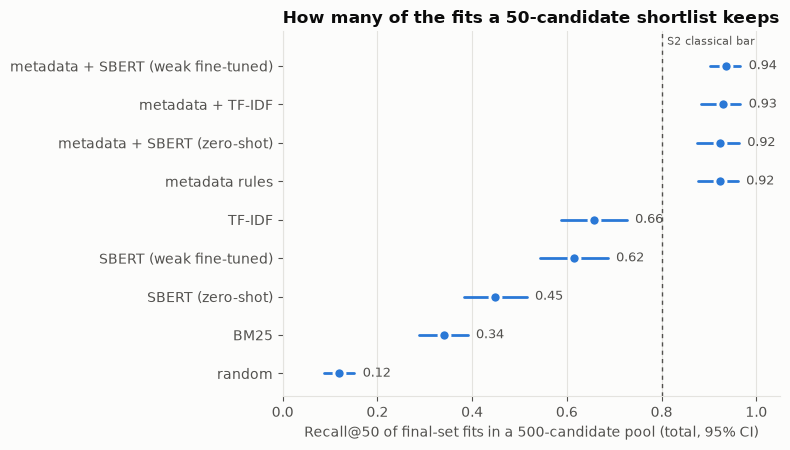

In [3]:
table = pd.DataFrame(rows).sort_values("recall@50")
fig, ax = plt.subplots(figsize=(8, 0.4 * len(table) + 1))
lookup = {n: {(x["metric"], x["scope"]): x for x in figs} for n, figs in pilot["retrievers"].items()}
reporting.dot_ci(ax, list(table.retriever)[::-1],
                 [lookup[n][("recall@50", "total")]["value"] for n in table.retriever][::-1],
                 [lookup[n][("recall@50", "total")]["ci_low"] for n in table.retriever][::-1],
                 [lookup[n][("recall@50", "total")]["ci_high"] for n in table.retriever][::-1],
                 ref=0.8, ref_label="S2 classical bar")
ax.set_xlabel("Recall@50 of final-set fits in a 500-candidate pool (total, 95% CI)")
ax.set_title("How many of the fits a 50-candidate shortlist keeps")
ax.set_xlim(0, 1.05)
plt.tight_layout()

## Retrieve-then-rank (C12)

In [4]:
rows = []
for name, figs in pilot["retrieve_then_rank"].items():
    for x in figs:
        if "comparison" in x:
            rows.append({"pipeline": name, "Δ recall@10 vs retriever alone": x["delta"], "CI": x["ci"], "n_jd": x["n_jd"]})
pd.DataFrame(rows)

,pipeline,Δ recall@10 vs retriever alone,CI,n_jd
0,metadata + TF-IDF → cross-encoder (A1) (top 50),-0.327818,"[-0.405549, -0.250611]",59
1,metadata + TF-IDF → cross-encoder (weak) (top 50),-0.254136,"[-0.333162, -0.168367]",59
2,TF-IDF → cross-encoder (A1) (top 50),-0.172505,"[-0.228513, -0.118381]",59
3,TF-IDF → cross-encoder (weak) (top 50),-0.097579,"[-0.166809, -0.025877]",59


## A1, the secondary benchmark (A13 caveat)

In [5]:
print(a1["note_a13"])
pd.DataFrame([{"system": n, "per-JD AUC": b["per_jd_auc"]["value"],
               "Recall@10 (graded, N100)": b["recall@10_graded_N100"]["value"],
               "macro-F1": b.get("classifier", {}).get("macro_f1")} for n, b in a1["systems"].items()])

A1's labels do not reproduce (A13): blind readers agree with them at chance. These figures measure agreement with A1's labelling process, not screening quality.


,system,per-JD AUC,"Recall@10 (graded, N100)",macro-F1
0,random,0.479091,0.080640,NaN
1,TF-IDF,0.648827,0.354194,NaN
2,BM25,0.588030,0.253722,NaN
3,SBERT (zero-shot),0.678311,0.292208,NaN
4,SBERT (weak fine-tuned),0.635573,0.281654,NaN
5,cross-encoder (A1),0.627843,0.117735,0.573647
6,cross-encoder (weak),0.447007,0.078621,0.479041


## Latency (S4)

In [6]:
pd.Series({k: v for k, v in latency.items() if not isinstance(v, dict)})

pipeline                                                                 metadata + TF-IDF
candidates_per_role                                                                    500
roles_timed                                                                              5
fit_seconds_once                                                                     16.59
median_seconds_per_role                                                               0.84
median_ms_per_candidate                                                               1.68
proposal_budget_seconds_per_candidate                                                120.0
note                                     System time only (ranking + evidence, no seman...
dtype: object